# L2: Integração Externa: Relatório de Progresso do Projeto

## Initial Imports

In [1]:
# type: ignore
# Warning control
import warnings
warnings.filterwarnings('ignore')

# Load environment variables
from helper import load_env
load_env()

import os
import json
import yaml
from crewai import Agent, Task, Crew

## Load OpenAI Model

In [2]:
os.environ['OPENAI_MODEL_NAME'] = 'gpt-4o-mini'

## Loading Tasks and Agents YAML files

In [3]:
# Define file paths for YAML configurations
files = {
    'agents': 'config/agents.yaml',
    'tasks': 'config/tasks.yaml'
}

# Load configurations from YAML files
configs = {}
for config_type, file_path in files.items():
    with open(file_path, 'r') as file:
        configs[config_type] = yaml.safe_load(file)

# Assign loaded configurations to specific variables
agents_config = configs['agents']
tasks_config = configs['tasks']

## Creating Custom Tools

In [ ]:
# type: ignore
from crewai.tools import BaseTool
import requests

class BoardDataFetcherTool(BaseTool):
    name: str = "Coletor de Dados do Quadro Trello"
    description: str = "Coleta dados dos cartões, comentários e atividades de um quadro Trello."

    api_key: str = os.environ['TRELLO_API_KEY']
    api_token: str = os.environ['TRELLO_API_TOKEN']
    board_id: str = os.environ['TRELLO_BOARD_ID']

    def _run(self) -> dict:
        """
        Coleta todos os cartões do quadro Trello especificado.
        """
        url = f"{os.getenv('DLAI_TRELLO_BASE_URL', 'https://api.trello.com')}/1/boards/{self.board_id}/cards"

        query = {
            'key': self.api_key,
            'token': self.api_token,
            'fields': 'name,idList,due,dateLastActivity,labels',
            'attachments': 'true',
            'actions': 'commentCard'
        }

        response = requests.get(url, params=query)

        if response.status_code == 200:
            return response.json()
        else:
            # Caso haja falha, como timeout ou outros problemas
            return json.dumps([{'id': '66c3bfed69b473b8fe9d922e', 'name': 'Análise dos resultados do CSV', 'idList': '66c308f676b057fdfbd5fdb3', 'due': None, 'dateLastActivity': '2024-08-19T21:58:05.062Z', 'labels': [], 'attachments': [], 'actions': []}, {'id': '66c3c002bb1c337f3fdf1563', 'name': 'Aprovar o planejamento', 'idList': '66c308f676b057fdfbd5fdb3', 'due': '2024-08-16T21:58:00.000Z', 'dateLastActivity': '2024-08-19T21:58:57.697Z', 'labels': [{'id': '66c305ea10ea602ee6e03d47', 'idBoard': '66c305eacab50fcd7f19c0aa', 'name': 'Urgente', 'color': 'red', 'uses': 1}], 'attachments': [], 'actions': [{'id': '66c3c021f3c1bb157028f53d', 'idMemberCreator': '65e5093d0ab5ee98592f5983', 'data': {'text': 'Isso foi mais difícil do que esperava, está tarde', 'textData': {'emoji': {}}, 'card': {'id': '66c3c002bb1c337f3fdf1563', 'name': 'Aprovar o planejamento', 'idShort': 5, 'shortLink': 'K3abXIMm'}, 'board': {'id': '66c305eacab50fcd7f19c0aa', 'name': '[Teste] Quadro CrewAI', 'shortLink': 'Kc8ScQlW'}, 'list': {'id': '66c308f676b057fdfbd5fdb3', 'name': 'TODO'}}, 'appCreator': None, 'type': 'commentCard', 'date': '2024-08-19T21:58:57.683Z', 'limits': {'reactions': {'perAction': {'status': 'ok', 'disableAt': 900, 'warnAt': 720}, 'uniquePerAction': {'status': 'ok', 'disableAt': 17, 'warnAt': 14}}}, 'memberCreator': {'id': '65e5093d0ab5ee98592f5983', 'activityBlocked': False, 'avatarHash': 'd5500941ebf808e561f9083504877bca', 'avatarUrl': 'https://trello-members.s3.amazonaws.com/65e5093d0ab5ee98592f5983/d5500941ebf808e561f9083504877bca', 'fullName': 'João Moura', 'idMemberReferrer': None, 'initials': 'JM', 'nonPublic': {}, 'nonPublicAvailable': True, 'username': 'joaomoura168'}}]}, {'id': '66c3bff4a25b398ef1b6de78', 'name': 'Estrutura inicial da interface do aplicativo', 'idList': '66c3bfdfb851ad9ff7eee159', 'due': None, 'dateLastActivity': '2024-08-19T21:58:12.210Z', 'labels': [], 'attachments': [], 'actions': []}, {'id': '66c3bffdb06faa1e69216c6f', 'name': 'Planejamento do projeto', 'idList': '66c3bfe3151c01425f366f4c', 'due': None, 'dateLastActivity': '2024-08-19T21:58:21.081Z', 'labels': [], 'attachments': [], 'actions': []}])

class CardDataFetcherTool(BaseTool):
    name: str = "Coletor de Dados do Cartão Trello"
    description: str = "Coleta dados de um cartão específico do Trello."

    api_key: str = os.environ['TRELLO_API_KEY']
    api_token: str = os.environ['TRELLO_API_TOKEN']

    def _run(self, card_id: str) -> dict:
        url = f"{os.getenv('DLAI_TRELLO_BASE_URL', 'https://api.trello.com')}/1/cards/{card_id}"
        query = {
            'key': self.api_key,
            'token': self.api_token
        }
        response = requests.get(url, params=query)

        if response.status_code == 200:
            return response.json()
        else:
            # Caso haja falha, como timeout ou outros problemas
            return json.dumps({"error": "Falha ao buscar dados do cartão, não tente buscar mais dados do Trello"})


## Trello Board

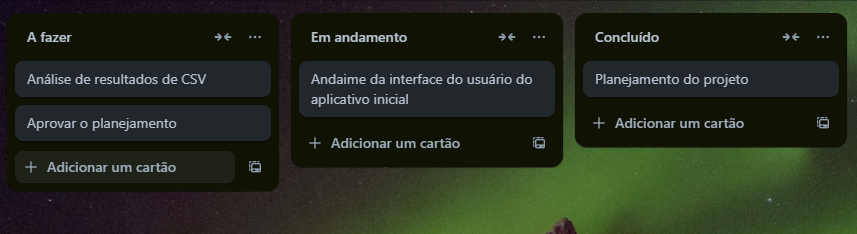

In [16]:
# Display the Trello screenshot
from IPython.display import Image, display

# Load and display the image
trello_image = Image(filename="trello.png")
display(trello_image)

## Create Crew, Agents and Tasks

In [17]:
# type: ignore
# Creating Agents
data_collection_agent = Agent(
  config=agents_config['data_collection_agent'],
  tools=[BoardDataFetcherTool(), CardDataFetcherTool()]
)

analysis_agent = Agent(
  config=agents_config['analysis_agent']
)

# Creating Tasks
data_collection = Task(
  config=tasks_config['data_collection'],
  agent=data_collection_agent
)

data_analysis = Task(
  config=tasks_config['data_analysis'],
  agent=analysis_agent
)

report_generation = Task(
  config=tasks_config['report_generation'],
  agent=analysis_agent,
)

# Creating Crew
crew = Crew(
  agents=[
    data_collection_agent,
    analysis_agent
  ],
  tasks=[
    data_collection,
    data_analysis,
    report_generation
  ],
  verbose=True
)

Overriding of current TracerProvider is not allowed


LLM value is None
LLM value is None


## Kickoff Crew

In [18]:
# Kick off the crew and execute the process
result = crew.kickoff()

# Agent: Especialista em Coleta de Dados
## Task: Criar uma compreensÃ£o inicial do projeto, suas principais caracterÃ­sticas e a equipe trabalhando nele. Use a ferramenta Trello Data Fetcher para coletar dados do quadro Trello.



# Agent: Especialista em Coleta de Dados
## Using tool: Coletor de Dados do Quadro Trello
## Tool Input: 
"{}"
## Tool Output: 
[{'id': '6793f5541e0d372574e77484', 'name': 'Análise de resultados de CSV', 'idList': '6793f4c5085eaf6d8683f6f2', 'due': None, 'dateLastActivity': '2025-01-24T20:17:24.465Z', 'labels': [], 'attachments': [], 'actions': []}, {'id': '6793f57010ea6ca0962ae0d5', 'name': 'Aprovar o planejamento', 'idList': '6793f4c5085eaf6d8683f6f2', 'due': None, 'dateLastActivity': '2025-01-24T20:17:52.280Z', 'labels': [], 'attachments': [], 'actions': []}, {'id': '6793f5ac642c6dd698a429d0', 'name': 'Andaime da interface do usuário do aplicativo inicial', 'idList': '6793f4c5085eaf6d8683f6f3', 'due': None, 'dateLastActivity': '2025-01-24T20:18:52.758Z', 

## Usage Metrics and Costs

In [13]:
import pandas as pd

costs = 0.150 * (crew.usage_metrics.prompt_tokens + crew.usage_metrics.completion_tokens) / 1_000_000
print(f"Total costs: ${costs:.4f}")

# Convert UsageMetrics instance to a DataFrame
df_usage_metrics = pd.DataFrame([crew.usage_metrics.dict()])
df_usage_metrics

Total costs: $0.0020


,total_tokens,prompt_tokens,cached_prompt_tokens,completion_tokens,successful_requests
0,13628,11928,5632,1700,8


## Report

In [14]:
from IPython.display import Markdown

markdown  = result.raw
Markdown(markdown)

# Relatório da Sprint - Projeto Iniciado

## Visão Geral da Sprint
A análise atual dos dados do projeto "Projeto Iniciado" revela uma série de bloqueios e atrasos que impactaram negativamente o progresso geral da sprint. É imperativo abordar essas questões para garantir que o projeto retome seu ritmo e alcance os objetivos estabelecidos.

## Resumo das Tarefas
Atualmente, as tarefas no Trello não apresentam status atualizados, como "Em andamento", "Concluído" ou "Aguardando". A falta de atualização das tarefas está contribuindo para a confusão e possíveis bloqueios na equipe.

## Problemas e Bloqueios Identificados
1. **Falta de Atualização de Status**: O status das tarefas não foi especificado, o que impede a visualização clara do progresso.
2. **Ausência de Descrições**: Muitas tarefas carecem de descrições claras, dificultando a compreensão dos requisitos e aumentando a possibilidade de atrasos devido a mal-entendidos.
3. **Data de Última Atividade**: Todas as tarefas mostram a mesma data de última atividade (24 de janeiro de 2025), indicando uma estagnação geral nas atividades do projeto.

## Progresso e Atrasos
O progresso do projeto está estagnado, refletindo a ausência de atualizações nas tarefas. A data de última atividade sugere que não houve movimentação significativa nas atividades, resultando em um atraso generalizado em relação ao cronograma planejado. As interdependências entre as tarefas de "Aprovar o planejamento" e "Planejamento do projeto" também precisam ser consideradas, pois ambas estão comprometidas.

## Visão Geral do Desempenho da Equipe
O desempenho da equipe parece estar sendo afetado pela falta de clareza nas tarefas e pela ausência de uma visão coerente do progresso. A falta de atualização e a ambiguidade nas descrições das atividades dificultam a execução das tarefas e a gestão do tempo da equipe.

## Itens de Ação e Recomendações
1. **Reunião de Status**: Agendar uma reunião com toda a equipe para discutir o status atual de cada tarefa e assegurar que todos os membros estejam cientes dos objetivos e prazos.
2. **Atualização do Trello**: Atualizar as informações do Trello com estados de progresso adequados e quaisquer bloqueios conhecidos para proporcionar uma visão clara do projeto.
3. **Clareza nas Descrições**: Incentivar a equipe a adicionar descrições detalhadas às atividades para minimizar mal-entendidos e proporcionar clareza sobre os requisitos e expectativas.
  
## Qualquer outra informação relevante ao projeto
É essencial que a equipe reavalie o planejamento do projeto, uma vez que o "Planejamento do projeto" não está avançando. A revisão imediata e a identificação de novos marcos poderão ser decisivas para revertê-los.

Essas ações são cruciais para reverter atrasos e garantir que o projeto continue em direção ao sucesso. A implementação dessas recomendações deve ser priorizada para restabelecer a confiança no cronograma e fomentar o engajamento da equipe.